# PROG8431 – Problem Analysis Workshop B
## K-Means Clustering: Ontario Property Dataset

## Group 5 

### Team Members

| Name | Student ID |
|------|------------|
| Asangika Hettiarachchi | 7461502 |
| Juan Antonio Sainz Galvez | 9072844 |
| Ved 

Dataset: `properties.csv`

This notebook follows the professor's lecture methods: z-score standardization, feature selection, K-Means assignment/update iterations, candidate K values from 2–10, elbow method, cluster sizes, centroids, within-cluster sum of squares, visualization, and cluster summaries.

No log transformation, geographic boundary filtering, or additional clustering method is used.

## 1. Load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

properties = pd.read_csv("./data/properties.csv")
print("Dataset shape:", properties.shape)
display(properties.head())

Dataset shape: (25351, 6)


,Unnamed: 0,Address,AreaName,Price ($),lat,lng
0,0,"86 Waterford Dr Toronto, ON",Richview,999888,43.679882,-79.544266
1,1,"#80 - 100 BEDDOE DR Hamilton, ON",Chedoke Park B,399900,43.250000,-79.904396
2,2,"213 Bowman Street Hamilton, ON",Ainslie Wood East,479000,43.251690,-79.919357
3,3,"102 NEIL Avenue Hamilton, ON",Greenford,285900,43.227161,-79.767403
4,6,"#1409 - 230 King St Toronto, ON",Downtown,362000,43.651478,-79.368118


## 2. Inspect and prepare

In [2]:
print(properties.info())
display(properties.describe(include="all").T)
display(properties.isna().sum().rename("Missing values").to_frame())
print("Duplicate rows:", properties.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 25351 entries, 0 to 25350
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  25351 non-null  int64  
 1   Address     25351 non-null  str    
 2   AreaName    24868 non-null  str    
 3   Price ($)   25351 non-null  int64  
 4   lat         25351 non-null  float64
 5   lng         25351 non-null  float64
dtypes: float64(2), int64(2), str(2)
memory usage: 1.2 MB
None


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,25351.0,NaN,NaN,NaN,42878.517613,31456.247046,0.0,19940.0,34037.0,61501.5,124929.0
Address,25351,23594,"223 Erb Street Waterloo, ON",16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AreaName,24868,1119,Downtown,830,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price ($),25351.0,NaN,NaN,NaN,564543.765137,847596.167337,0.0,219900.0,371900.0,619900.0,32500000.0
lat,25351.0,NaN,NaN,NaN,37.326614,82.858347,-999.0,43.401087,43.715977,44.466711,53.851017
lng,25351.0,NaN,NaN,NaN,-85.218379,73.093572,-999.0,-80.308159,-79.503342,-79.107326,1.074519


,Missing values
Unnamed: 0,0
Address,0
AreaName,483
Price ($),0
lat,0
lng,0


Duplicate rows: 0


For clustering, select **Price ($), lat, and lng**. Remove the exported index column if present, convert selected columns to numeric, and remove rows missing selected features. Keep the data without arbitrary geographic boundary filtering.

In [3]:
data = properties.drop(columns=["Unnamed: 0"], errors="ignore").copy()
features = ["Price ($)", "lat", "lng"]
for col in features:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data = data.dropna(subset=features)
data = data[data["Price ($)"] > 0].copy()

print("Rows used for clustering:", len(data))
display(data[features].describe())

Rows used for clustering: 25195


,Price ($),lat,lng
count,2.519500e+04,25195.000000,25195.000000
mean,5.680393e+05,37.412835,-85.143077
std,8.490477e+05,82.340123,72.636975
min,1.000000e+00,-999.000000,-999.000000
25%,2.249000e+05,43.406231,-80.313125
50%,3.750000e+05,43.717453,-79.496788
75%,6.240000e+05,44.477620,-79.100994
max,3.250000e+07,53.851017,1.074519


## 3. Standardize features

\[
z_i = \frac{x_i-\bar{x}}{\sigma}
\]

Standardization gives each feature mean approximately 0 and standard deviation approximately 1. This matters because K-Means uses distance and the selected features have different scales.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data[features])
scaled_data = pd.DataFrame(X_scaled, columns=features, index=data.index)
display(scaled_data.describe().round(3))

,Price ($),lat,lng
count,25195.000,25195.000,25195.000
mean,0.000,0.000,-0.000
std,1.000,1.000,1.000
min,-0.669,-12.587,-12.581
25%,-0.404,0.073,0.066
50%,-0.227,0.077,0.078
75%,0.066,0.086,0.083
max,37.610,0.200,1.187


## 4. Explore the data

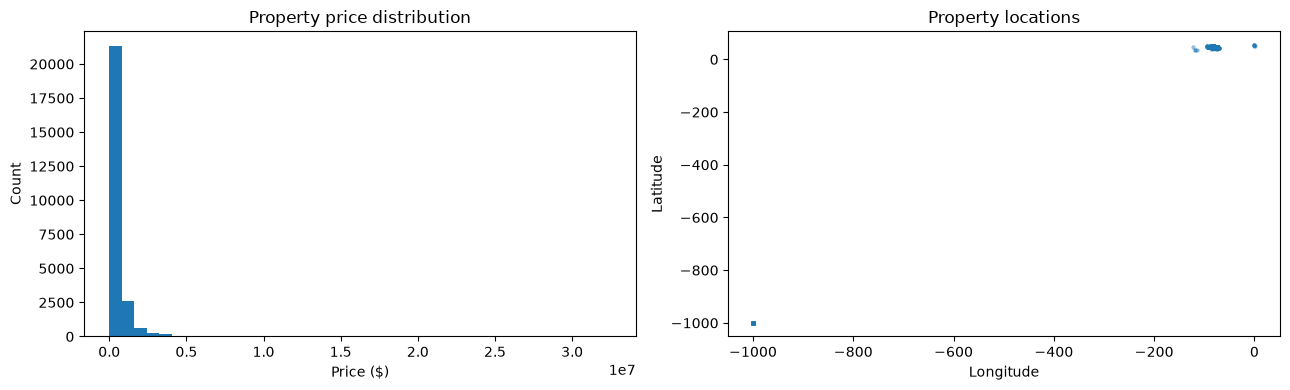

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(data["Price ($)"], bins=40)
axes[0].set_title("Property price distribution")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Count")
axes[1].scatter(data["lng"], data["lat"], s=5, alpha=0.35)
axes[1].set_title("Property locations")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
plt.tight_layout()
plt.show()

## 5. K-Means procedure

For a chosen K:
1. Initialize K centroids.
2. Assign each observation to its nearest centroid using Euclidean distance.
3. Recalculate each centroid as the mean of its assigned observations.
4. Repeat assignment and recalculation until the solution stabilizes.

The 2D Euclidean distance is:

\[
d=\sqrt{(x_2-x_1)^2+(y_2-y_1)^2}
\]

For multiple features, sum squared differences across all features before taking the square root.

## 6. Try K values and apply the elbow method

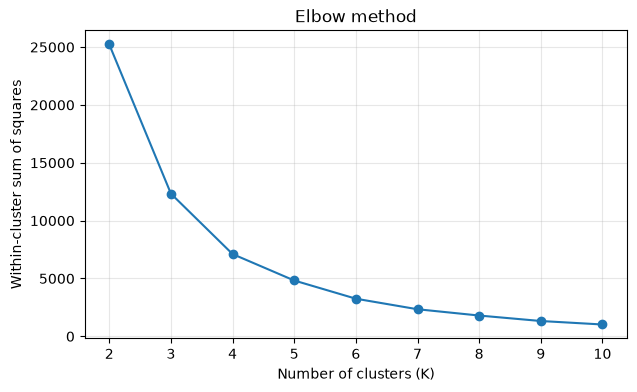

,K,Within-cluster SS
0,2,25222.224500
1,3,12331.460608
2,4,7110.404731
3,5,4825.987724
4,6,3252.527407
5,7,2341.420816
6,8,1797.997751
7,9,1325.218460
8,10,1023.572937


In [6]:
k_values = range(2, 11)
inertias = []
models = {}

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    models[k] = model
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Within-cluster sum of squares")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

display(pd.DataFrame({"K": list(k_values), "Within-cluster SS": inertias}))

Choose K after reviewing the elbow plot and cluster sizes. There is no universally correct K. Update `K_FINAL` to your chosen value.

In [7]:
K_FINAL = 3  # Change after reviewing your elbow plot.

final_model = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
data["Cluster"] = final_model.fit_predict(X_scaled)

## 7. Evaluate sizes, centroids, and within-cluster sum of squares

In [8]:
cluster_sizes = data["Cluster"].value_counts().sort_index()
print("Cluster sizes:")
display(cluster_sizes.rename("Number of properties").to_frame())

centroids_scaled = pd.DataFrame(
    final_model.cluster_centers_,
    columns=features,
    index=[f"Cluster {i}" for i in range(K_FINAL)]
)
print("Centroids (standardized feature units):")
display(centroids_scaled.round(3))

print("Total within-cluster sum of squares:", round(final_model.inertia_, 2))

Cluster sizes:


,Number of properties
Cluster,
0,761
1,24276
2,158


Centroids (standardized feature units):


,Price ($),lat,lng
Cluster 0,4.054,0.077,0.078
Cluster 1,-0.126,0.080,0.079
Cluster 2,-0.152,-12.587,-12.581


Total within-cluster sum of squares: 12331.46


## 8. Visualize clusters

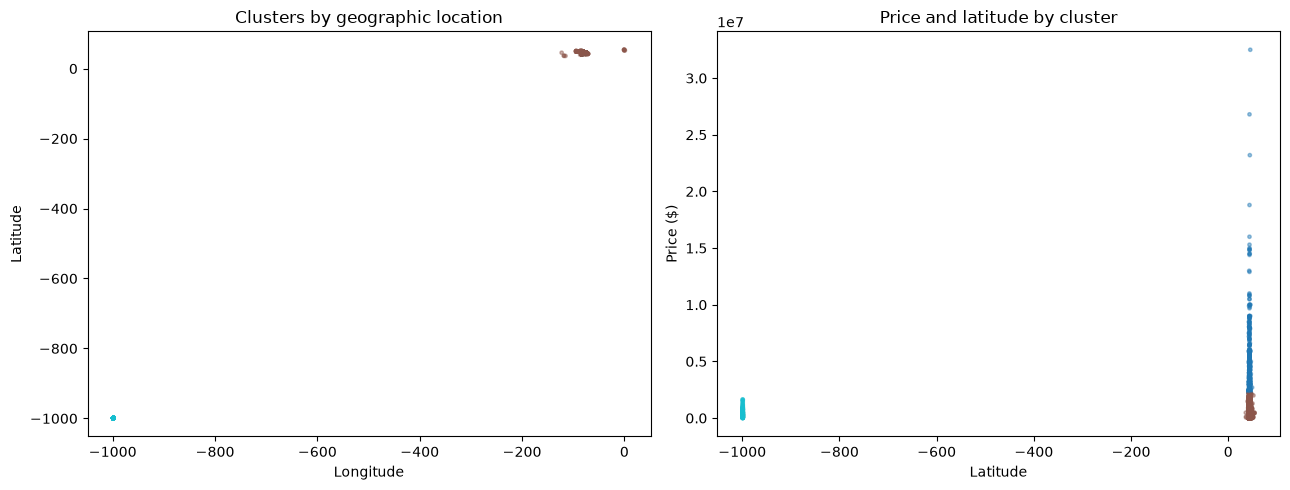

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(data["lng"], data["lat"], c=data["Cluster"], cmap="tab10", s=6, alpha=0.45)
axes[0].set_title("Clusters by geographic location")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[1].scatter(data["lat"], data["Price ($)"], c=data["Cluster"], cmap="tab10", s=6, alpha=0.45)
axes[1].set_title("Price and latitude by cluster")
axes[1].set_xlabel("Latitude")
axes[1].set_ylabel("Price ($)")
plt.tight_layout()
plt.show()

## 9. Summarize clusters

In [10]:
profile = data.groupby("Cluster").agg(
    Count=("Price ($)", "size"),
    Mean_Price=("Price ($)", "mean"),
    Median_Price=("Price ($)", "median"),
    Min_Price=("Price ($)", "min"),
    Max_Price=("Price ($)", "max"),
    Mean_Latitude=("lat", "mean"),
    Mean_Longitude=("lng", "mean")
).round(2)
display(profile)

,Count,Mean_Price,Median_Price,Min_Price,Max_Price,Mean_Latitude,Mean_Longitude
Cluster,,,,,,,
0,761,4009717.42,3128000.0,2245000,32500000,43.75,-79.49
1,24276,460987.54,364900.0,1,2200000,43.96,-79.37
2,158,439370.37,330000.0,2000,1650000,-999.00,-999.00


## 10. Interpretation and conclusion

For the selected solution (K_FINAL = 3), the clustering results show three groups with different price profiles and sizes:
- Cluster 0 has the highest median property price ($3,128,000) and contains 761 properties (3.0%). Its mean coordinates (latitude 43.75, longitude -79.49) place it in the Toronto area.
- Cluster 1 contains 24,276 properties (96.4%) and has a median price of $364,900. Its mean coordinates (latitude 43.96, longitude -79.37) are broadly in the Greater Toronto Area.
- Cluster 2 has the lowest median price ($330,000) and contains 158 properties (0.6%). However, its mean latitude and longitude are both -999, indicating invalid coordinate values rather than a meaningful geographic centroid.
Overall, the clusters show a clear high-price group (Cluster 0) and a much larger lower-price group (Cluster 1), but the solution is highly imbalanced. Because invalid coordinates were retained, Cluster 2 is not geographically interpretable and the geographic clustering results should be treated as preliminary.

